# CSE422 Lab Project: Software Quality Classification

This executed notebook analyzes software_quality_dataset.csv and follows the supplied project template.

Scope:

- full dataset audit and EDA;
- leakage-safe missing-value imputation, encoding, and scaling;
- stratified 80/20 split with five-fold training-only cross-validation;
- four selected classifiers: KNN, Logistic Regression, Naive Bayes, and Neural Network;
- hyperparameter selection by training-only cross-validation accuracy;
- accuracy percentages, macro precision, macro recall, macro F1, confusion matrices, and multiclass ROC/AUC;
- KMeans clustering with K diagnostics, silhouette score, ARI, NMI, and PCA visualization.

The selected scope satisfies the template requirement to apply Neural Network plus at least two other models. Linear Regression is excluded because Quality_Label is categorical, and Decision Tree is omitted from this focused revision.

## Reproducibility

The companion module software_quality_workflow.py contains the complete analysis code. Keep it and software_quality_dataset.csv beside this notebook. The fixed random seed is 42.

Dataset: 1600 rows, 8 predictors
Training/test: 1280/320
Logistic Regression    CV accuracy=35.39% | Test accuracy=35.31% | Test F1=17.40% | AUC=0.513
Naive Bayes            CV accuracy=35.39% | Test accuracy=36.25% | Test F1=35.46% | AUC=0.525
KNN                    CV accuracy=35.00% | Test accuracy=32.50% | Test F1=31.82% | AUC=0.490
Neural Network         CV accuracy=34.84% | Test accuracy=32.50% | Test F1=31.71% | AUC=0.502
Saved software_quality_outputs/analysis_results.json


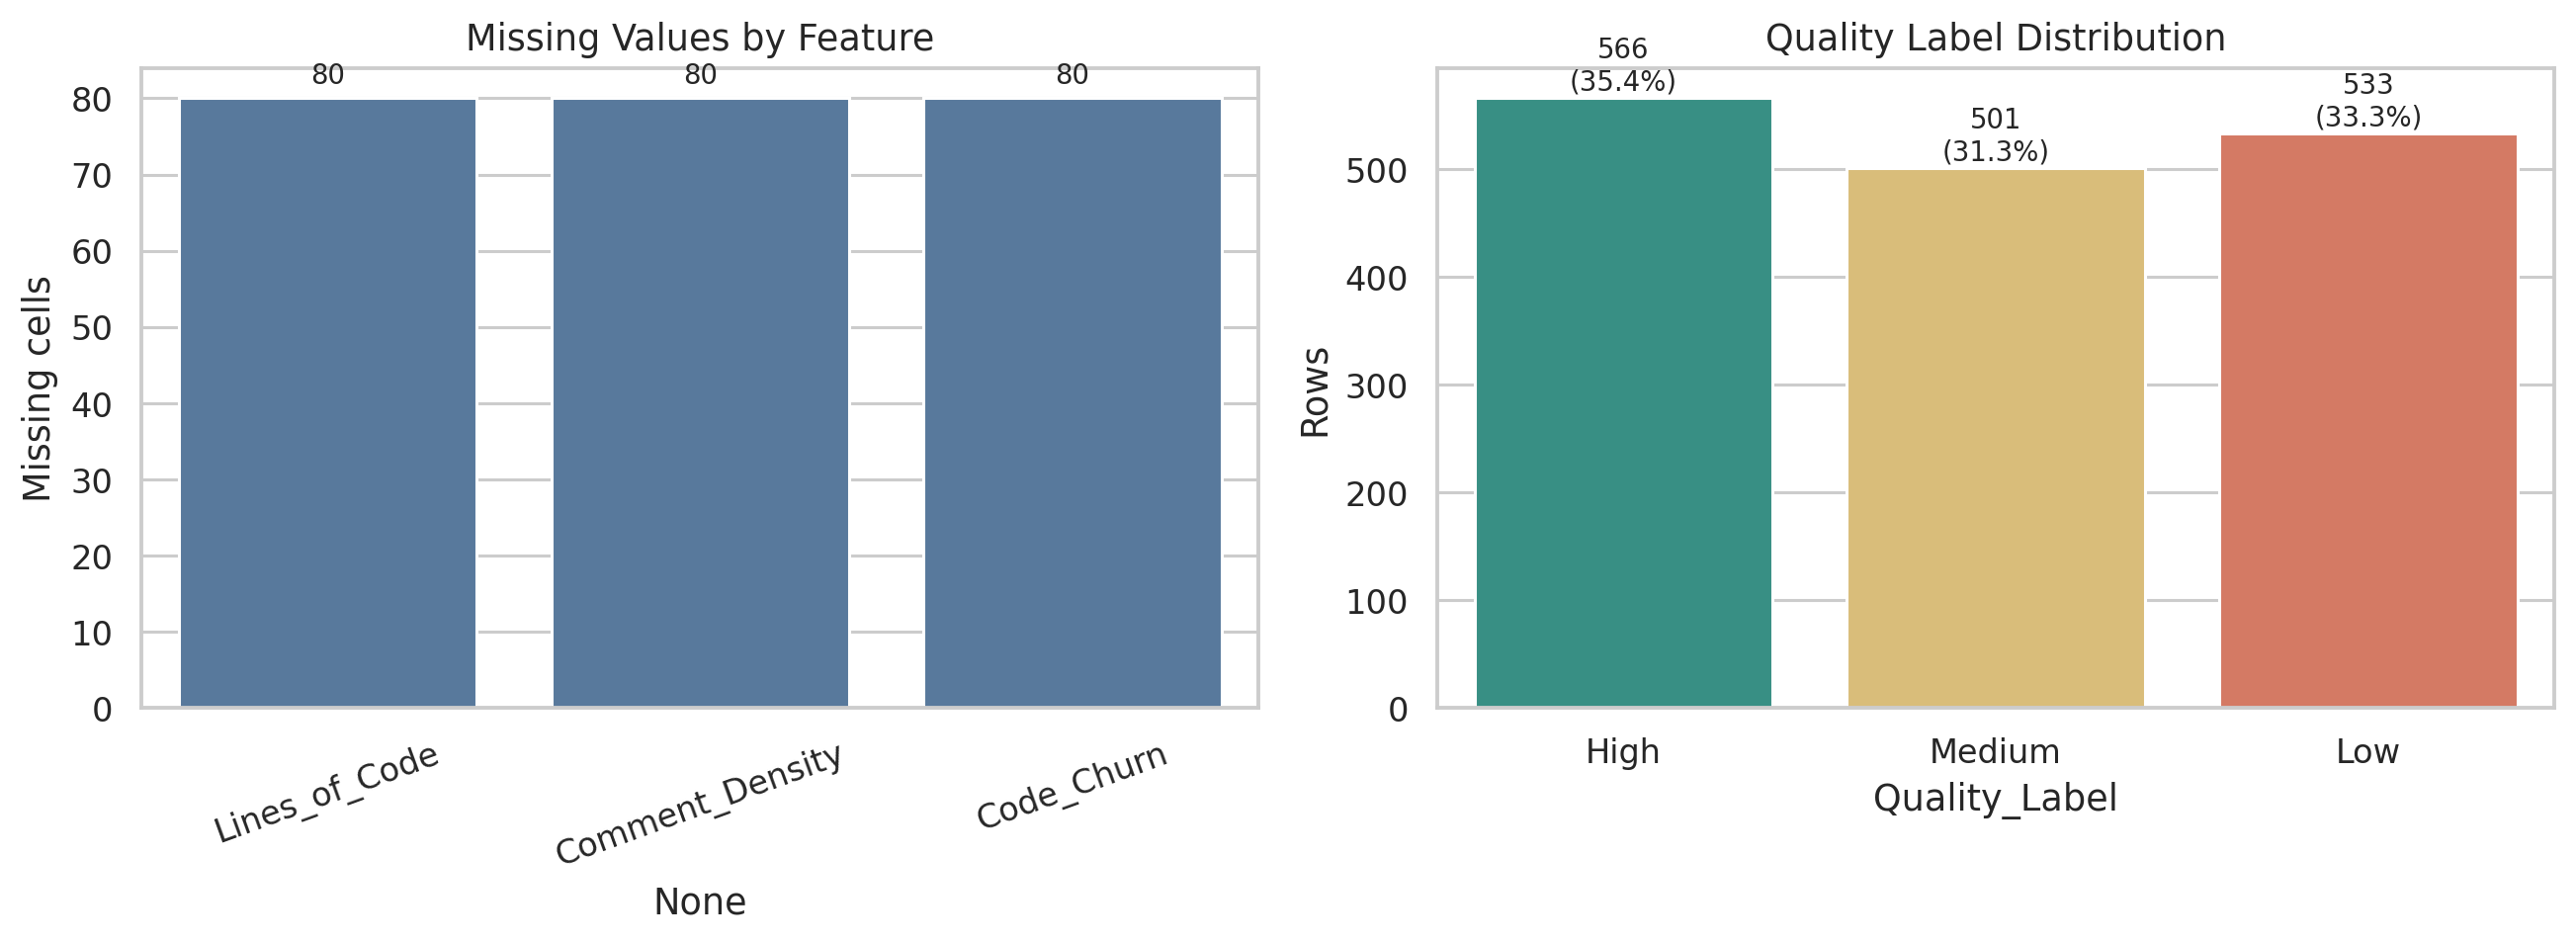

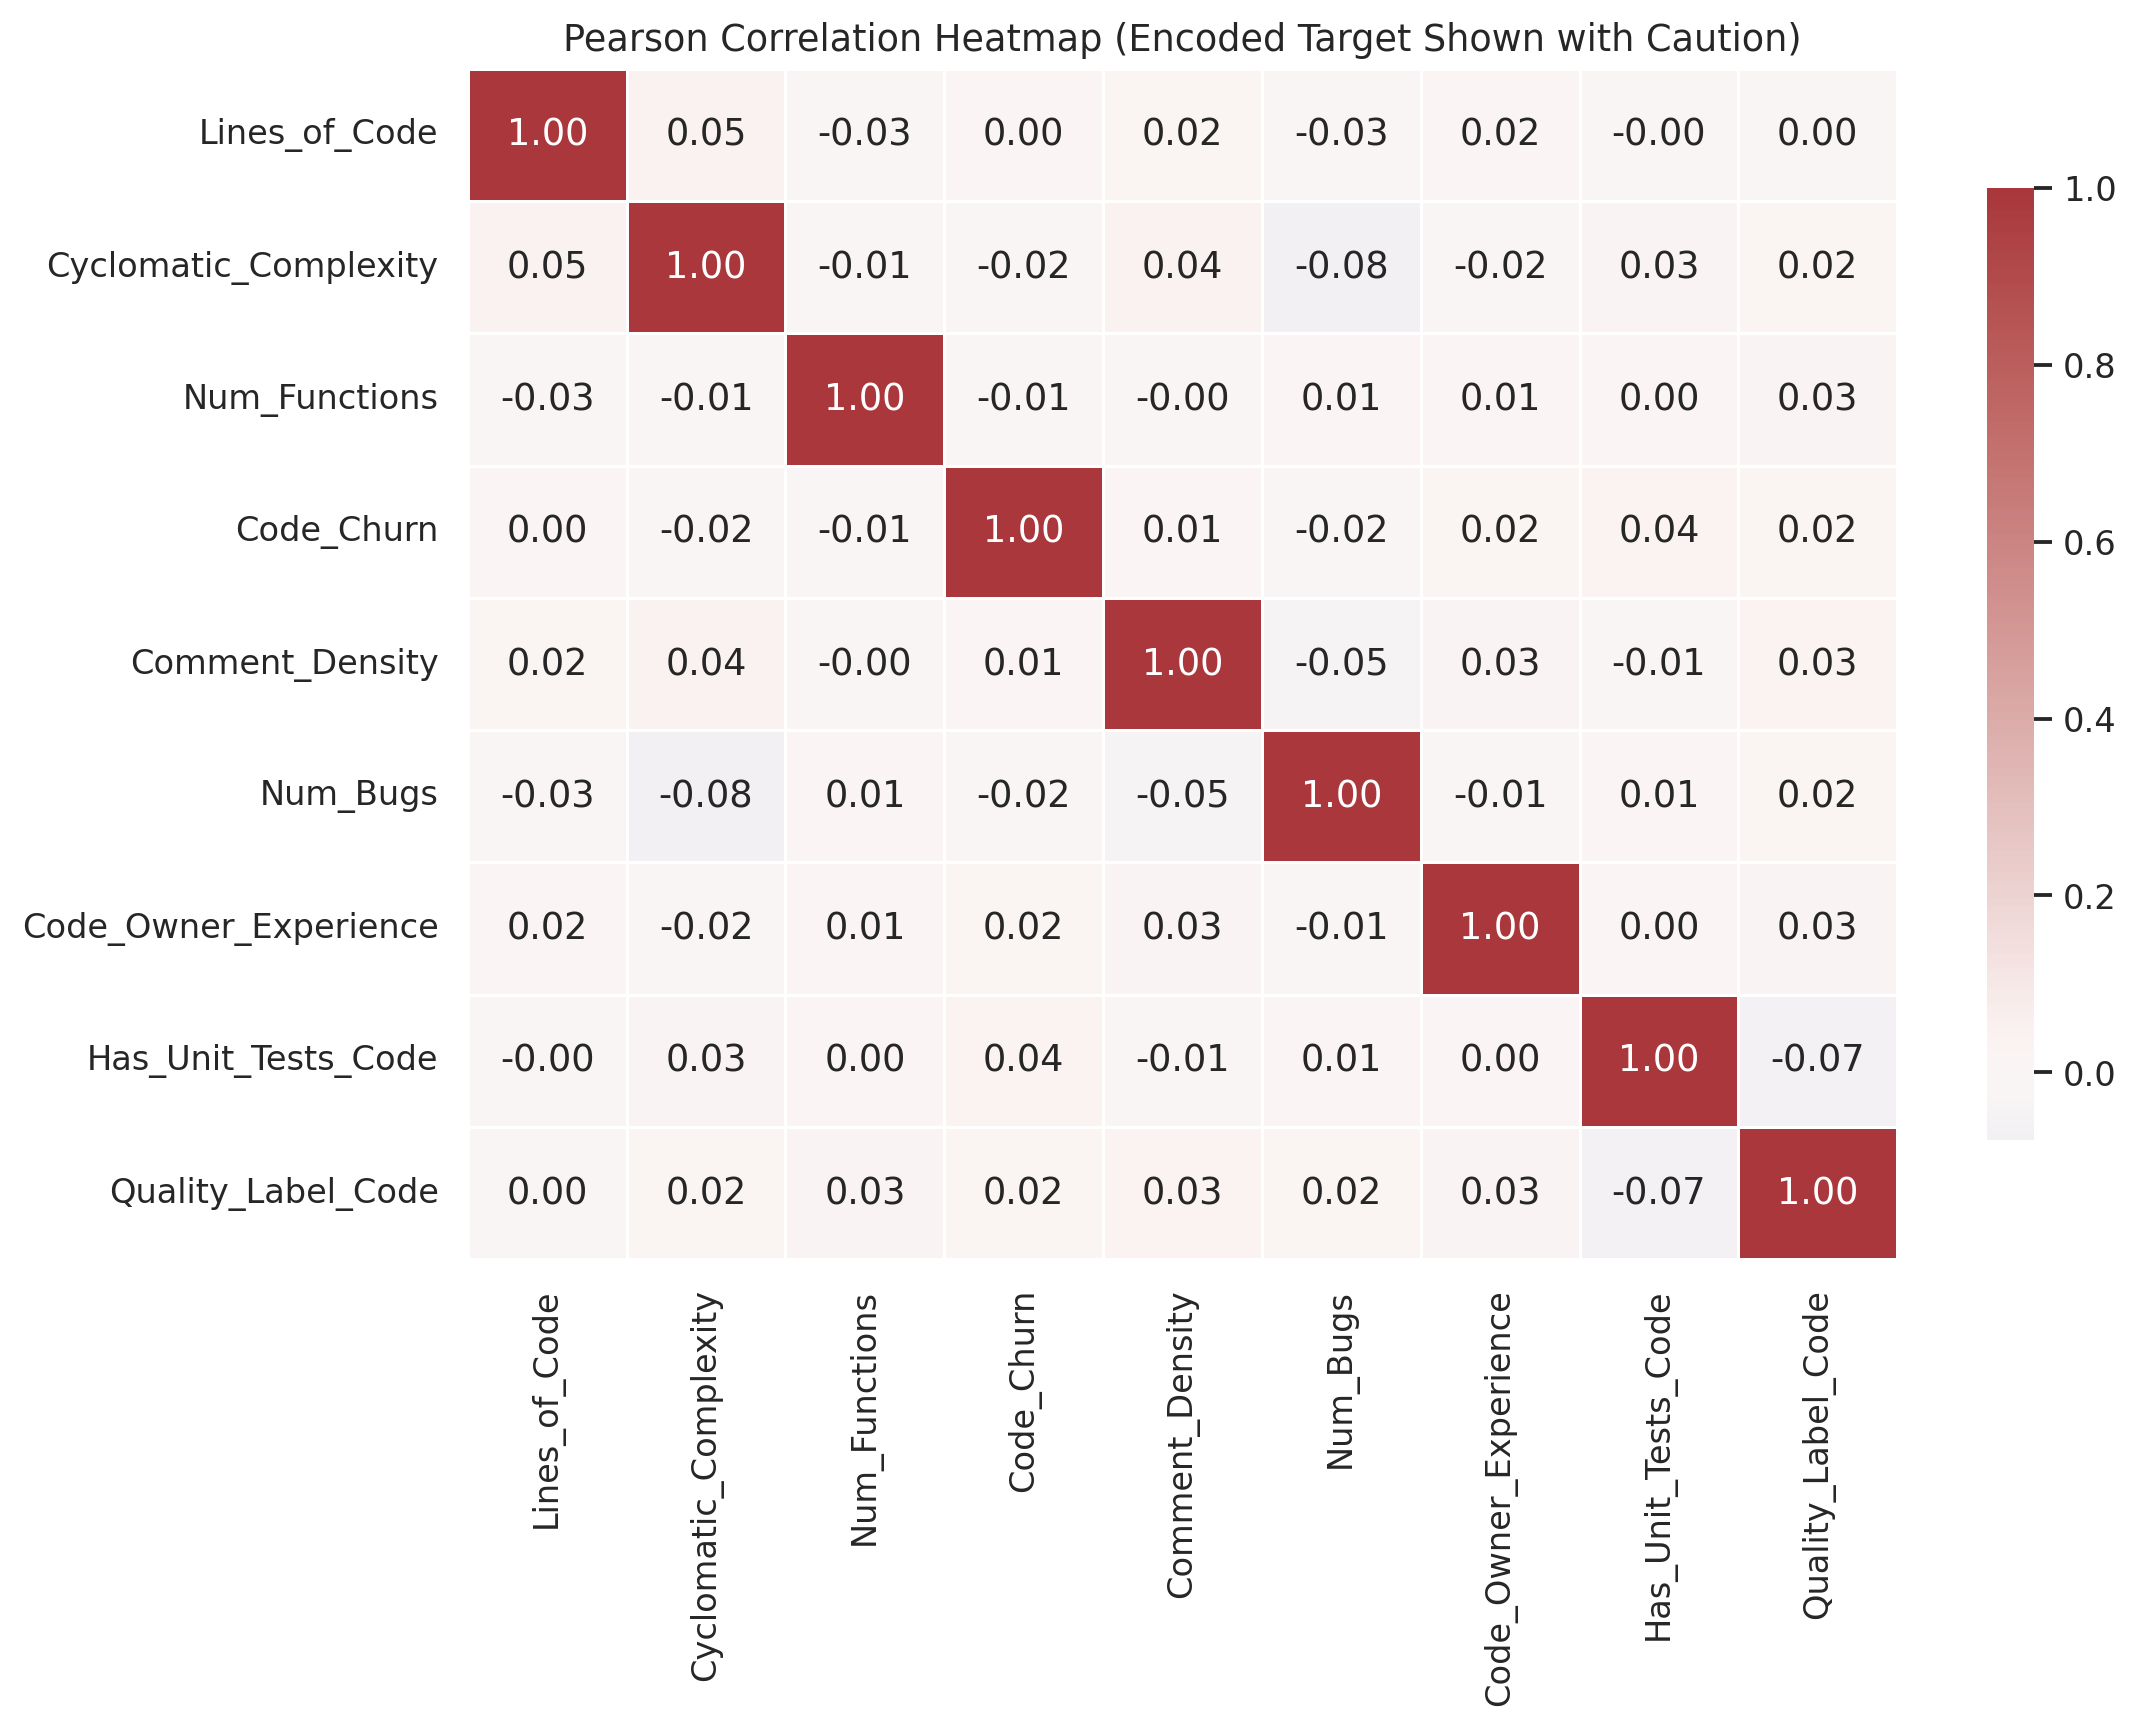

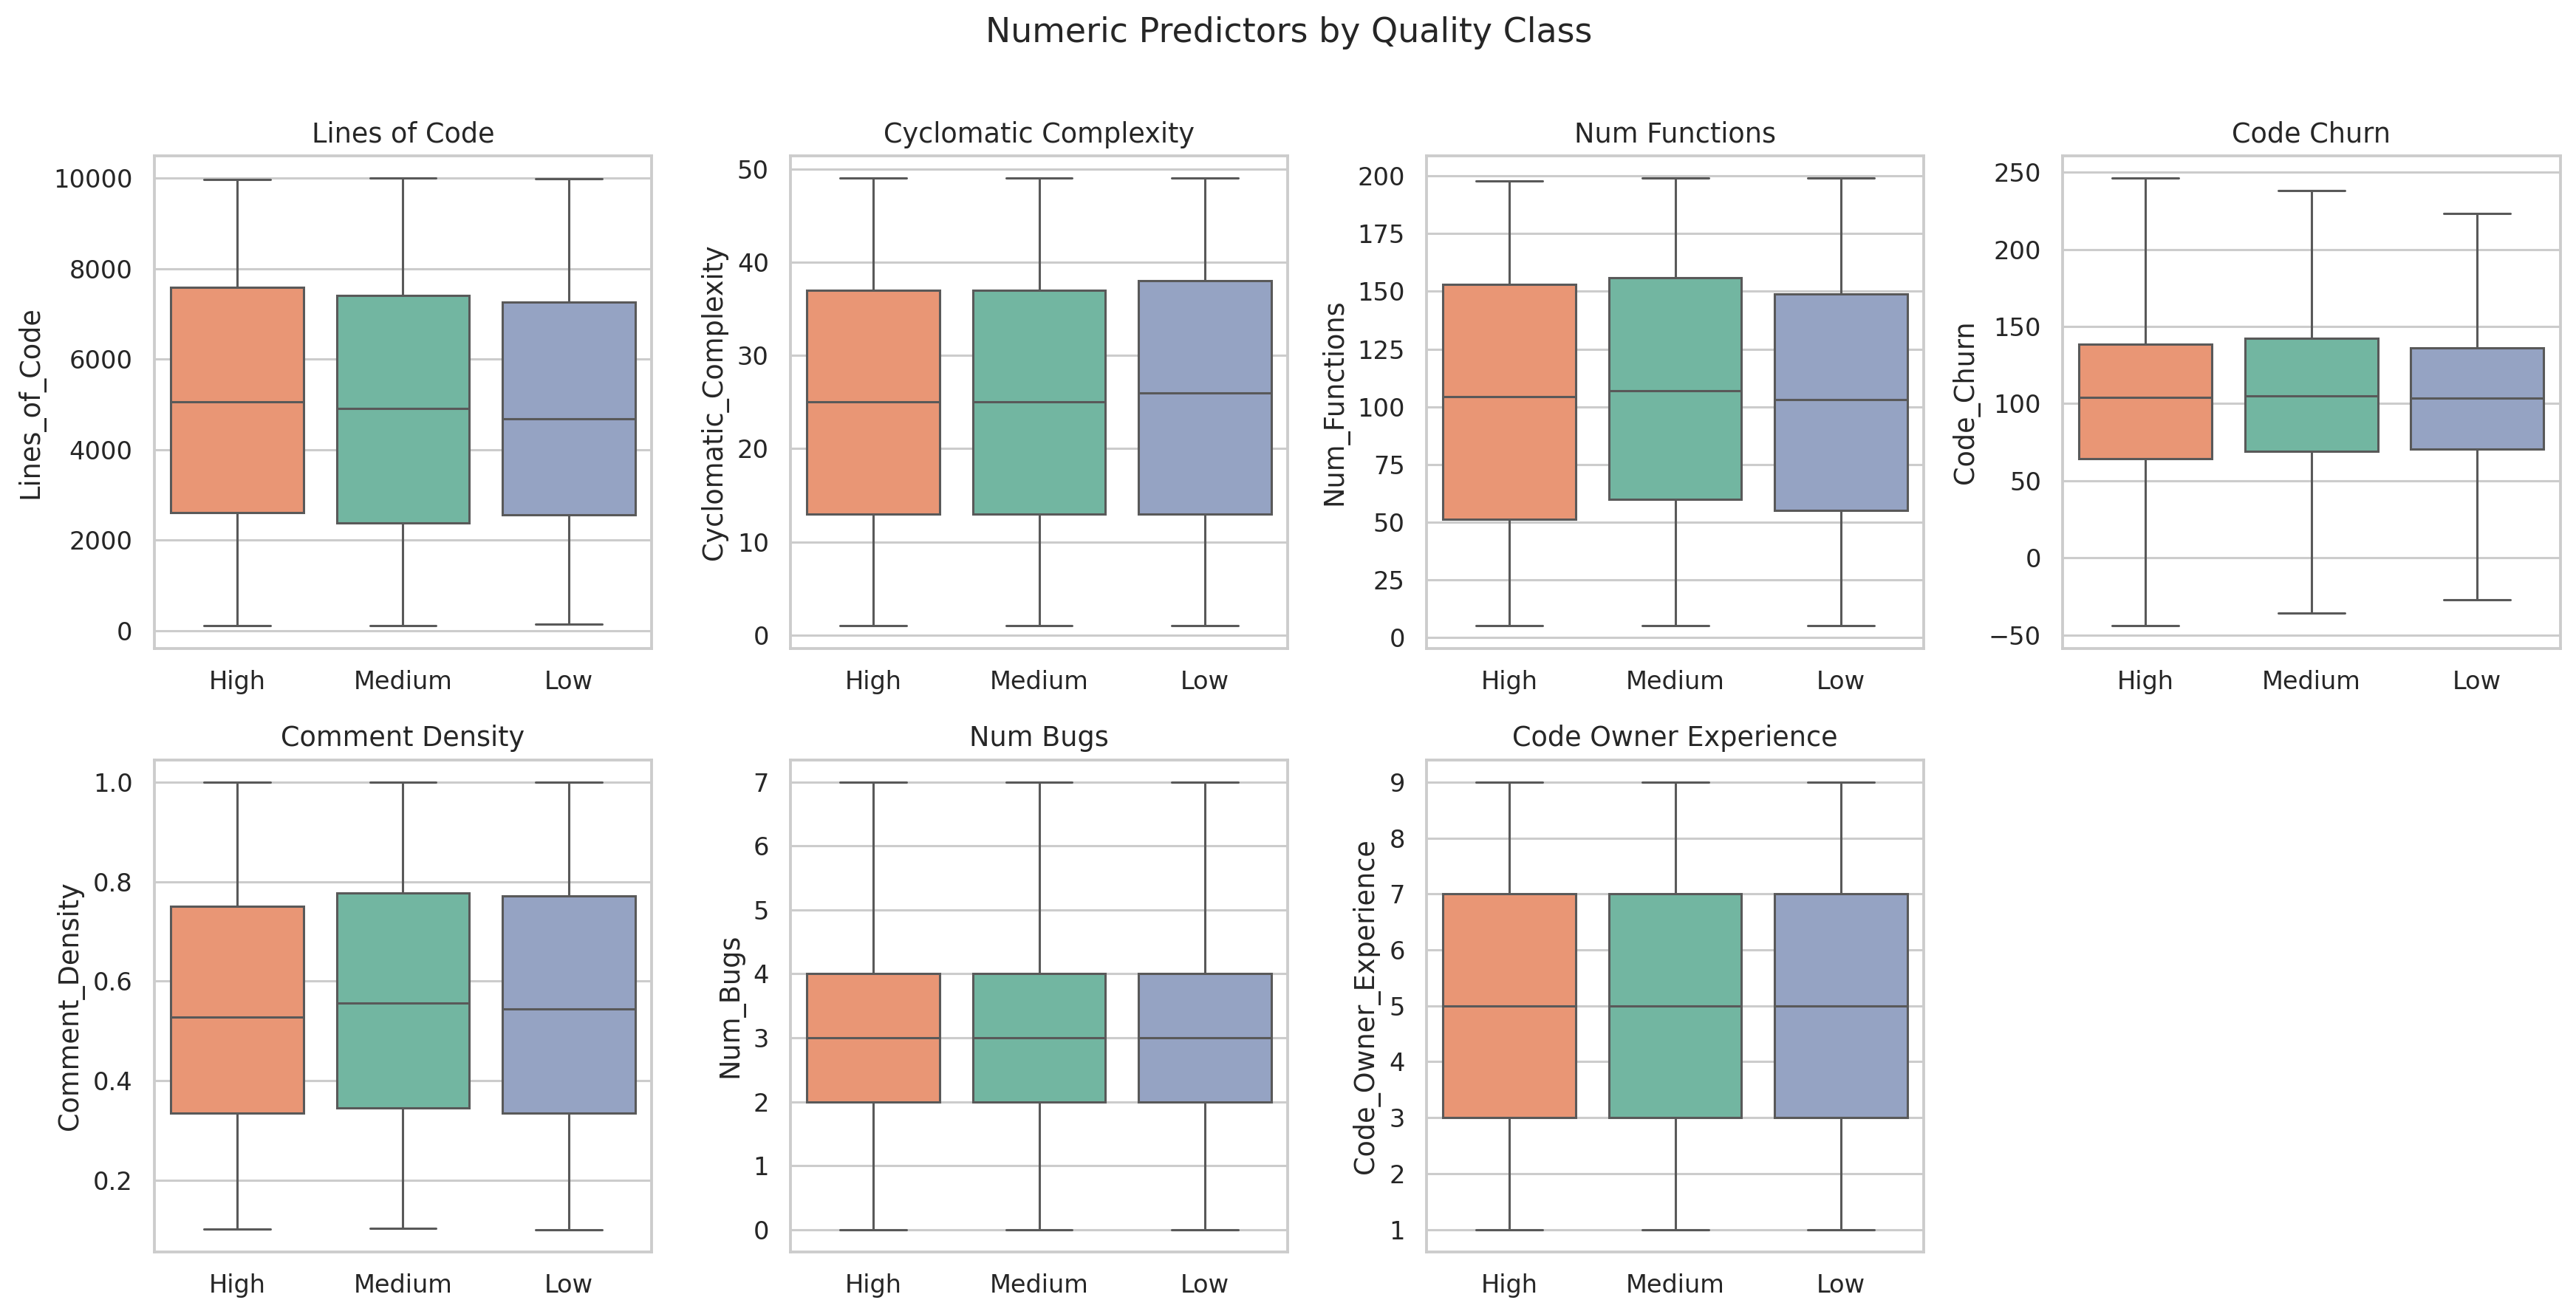

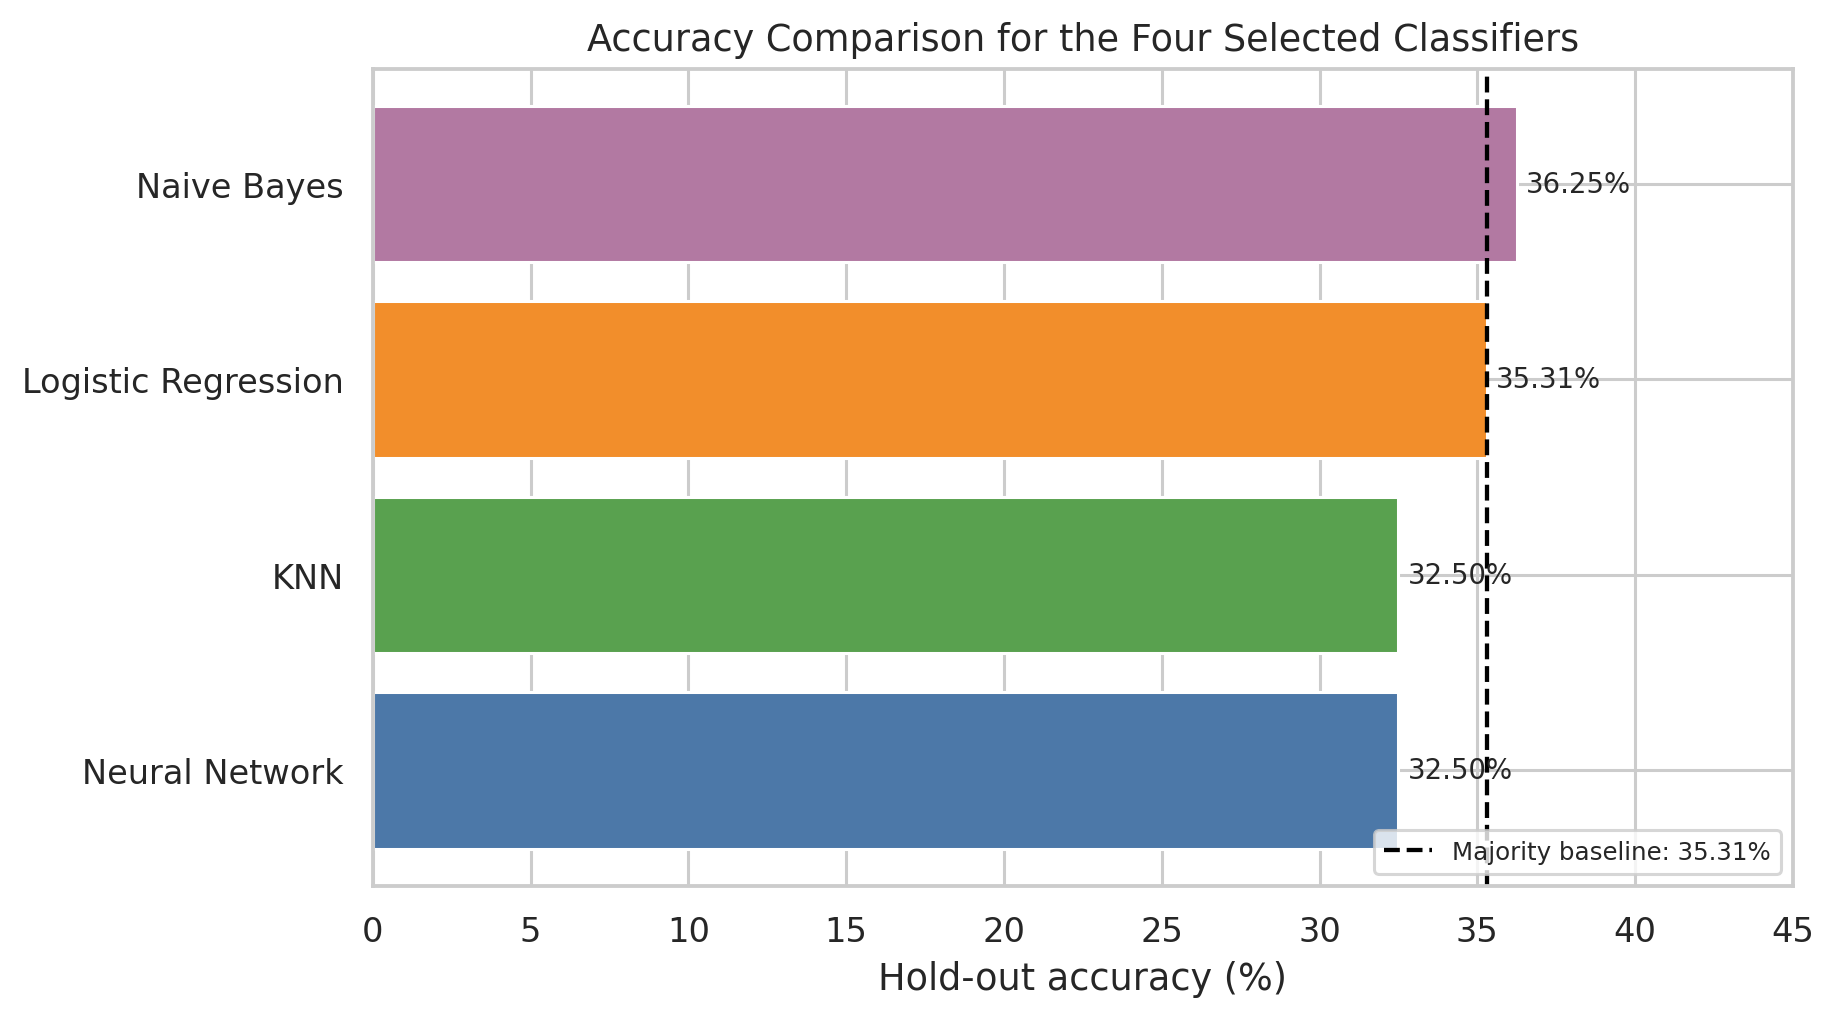

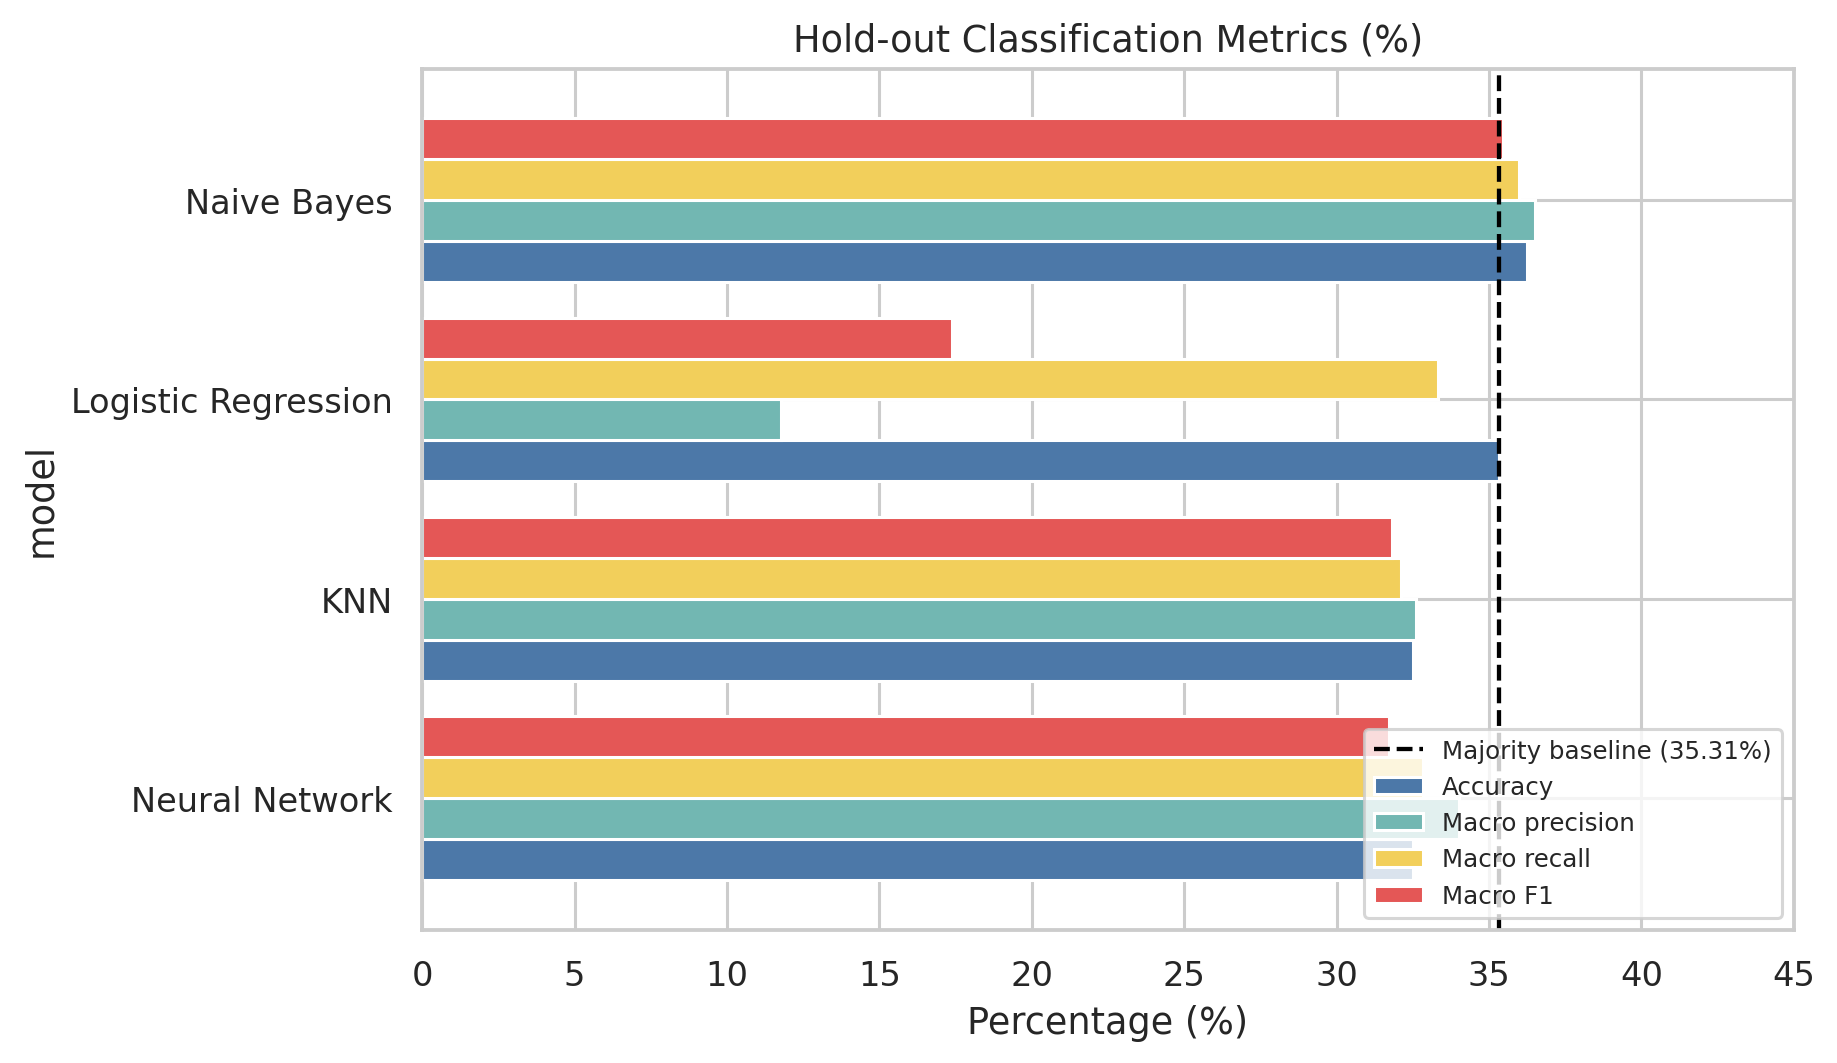

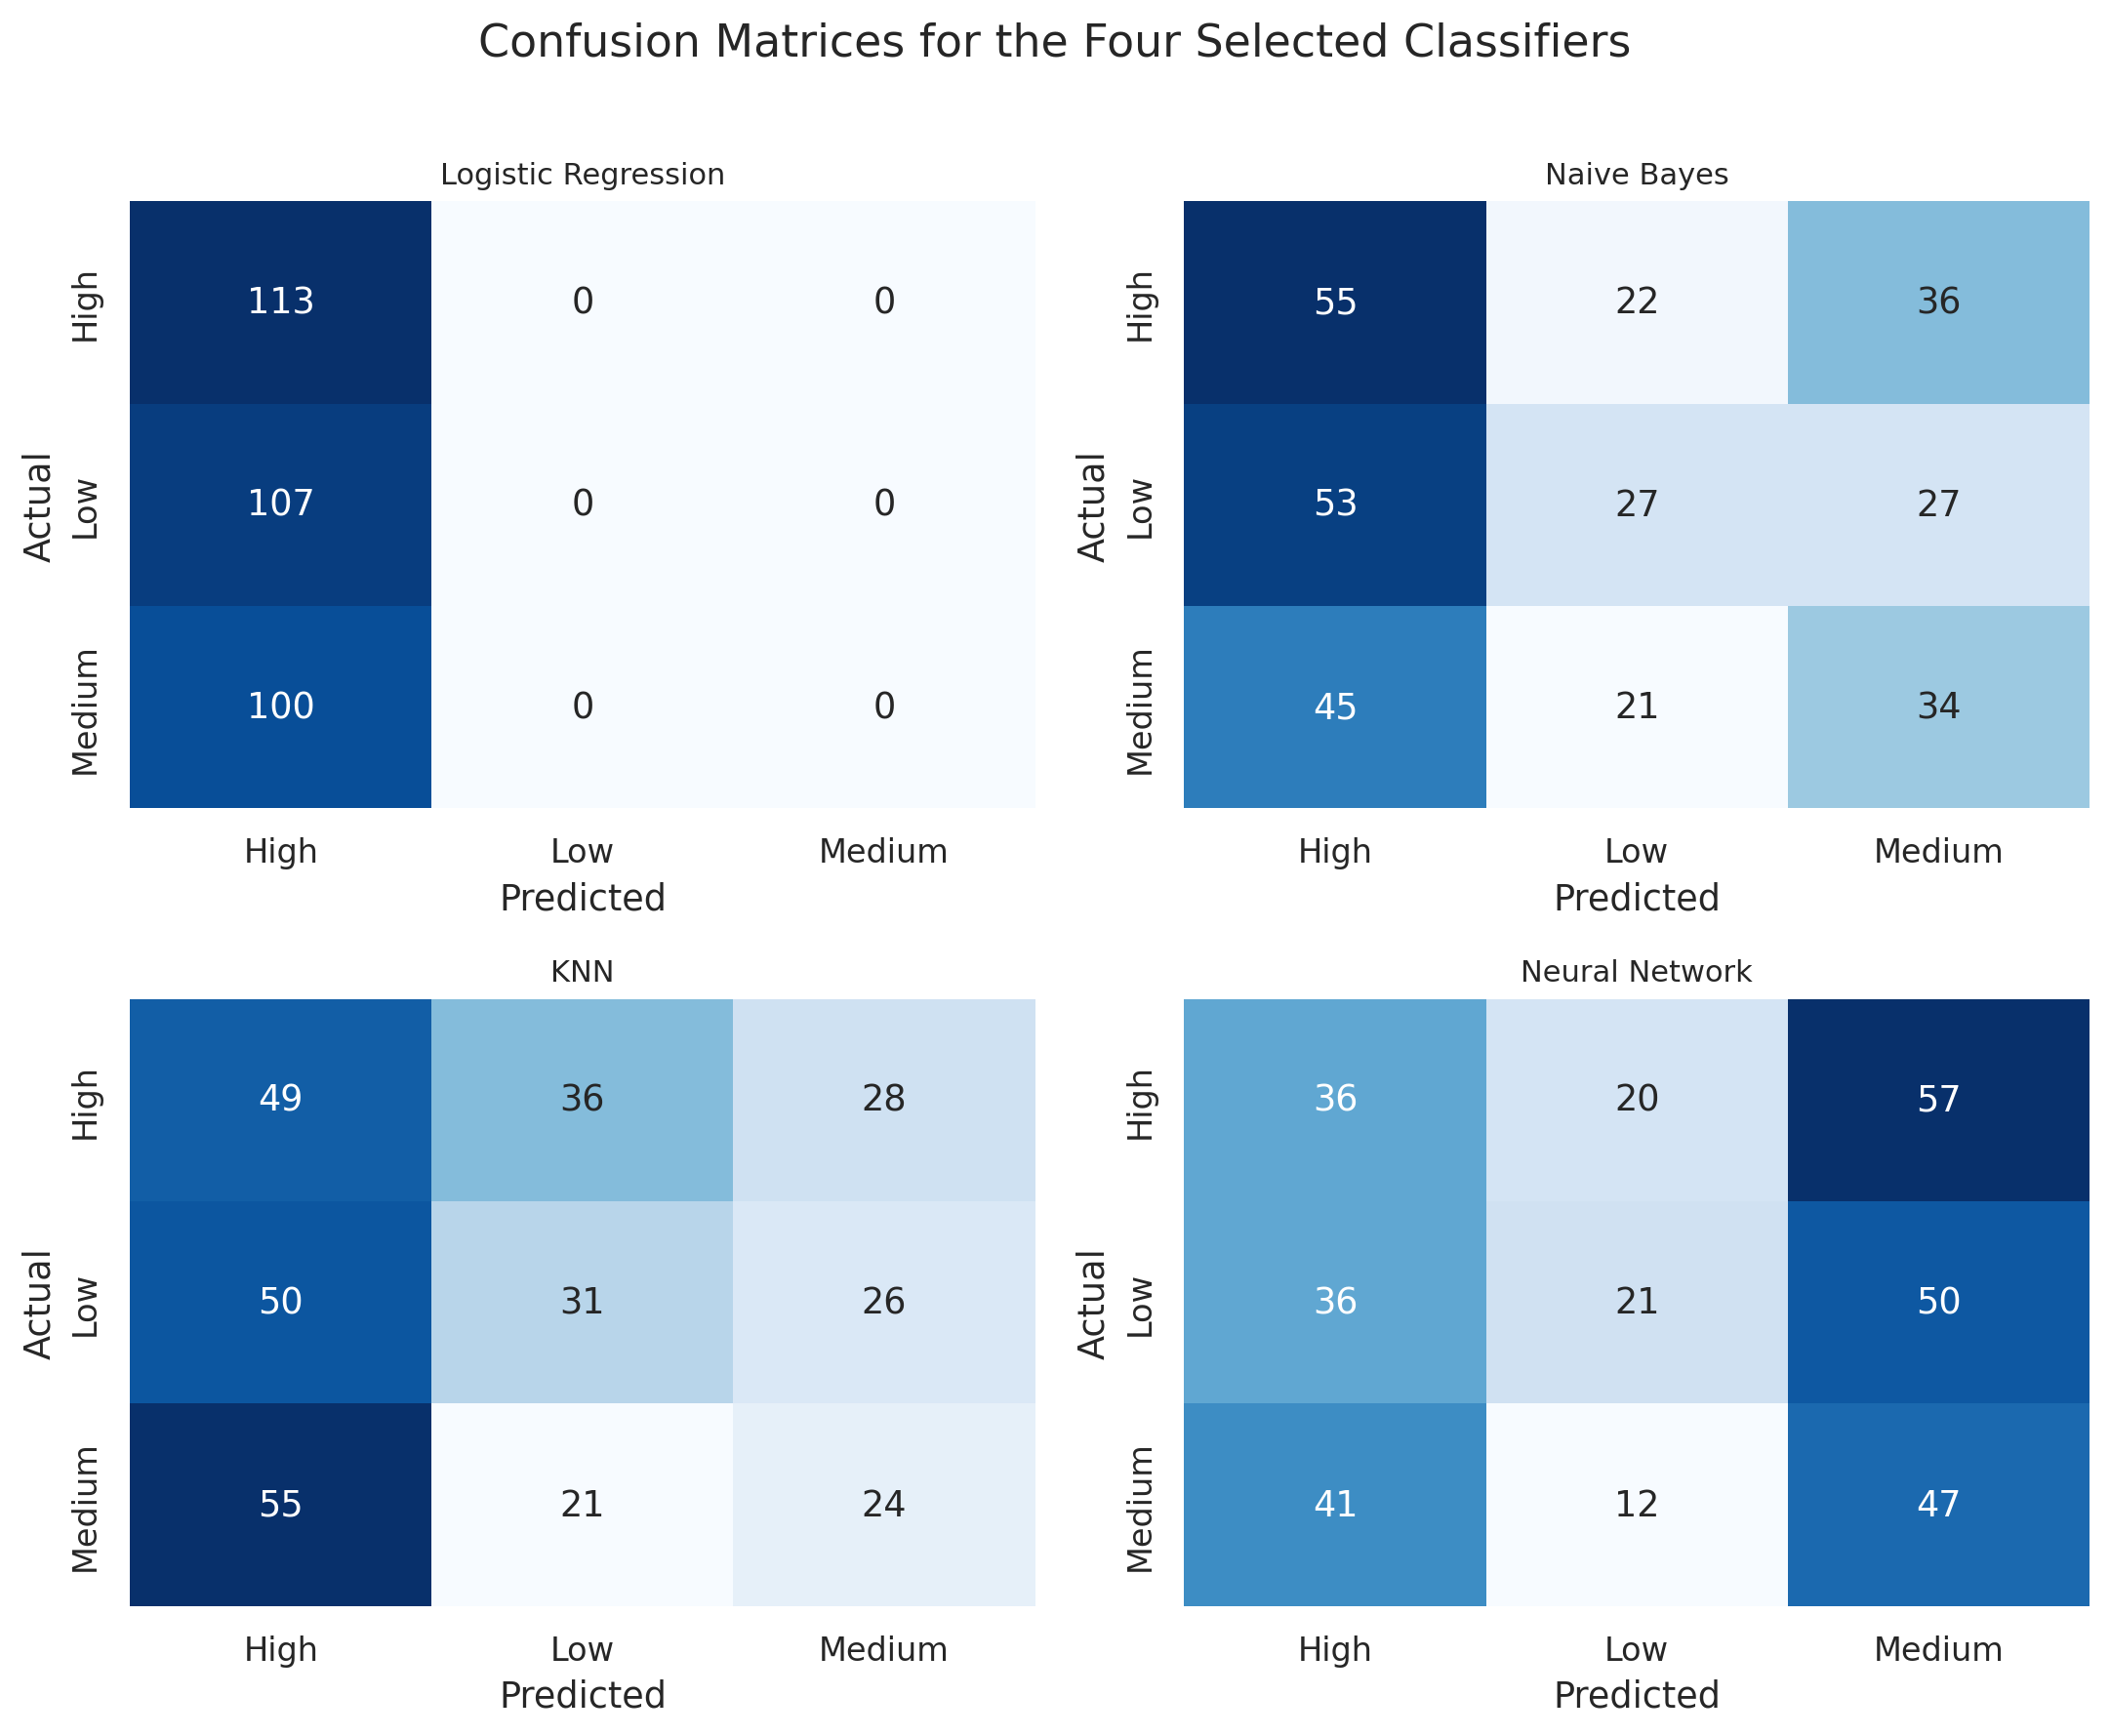

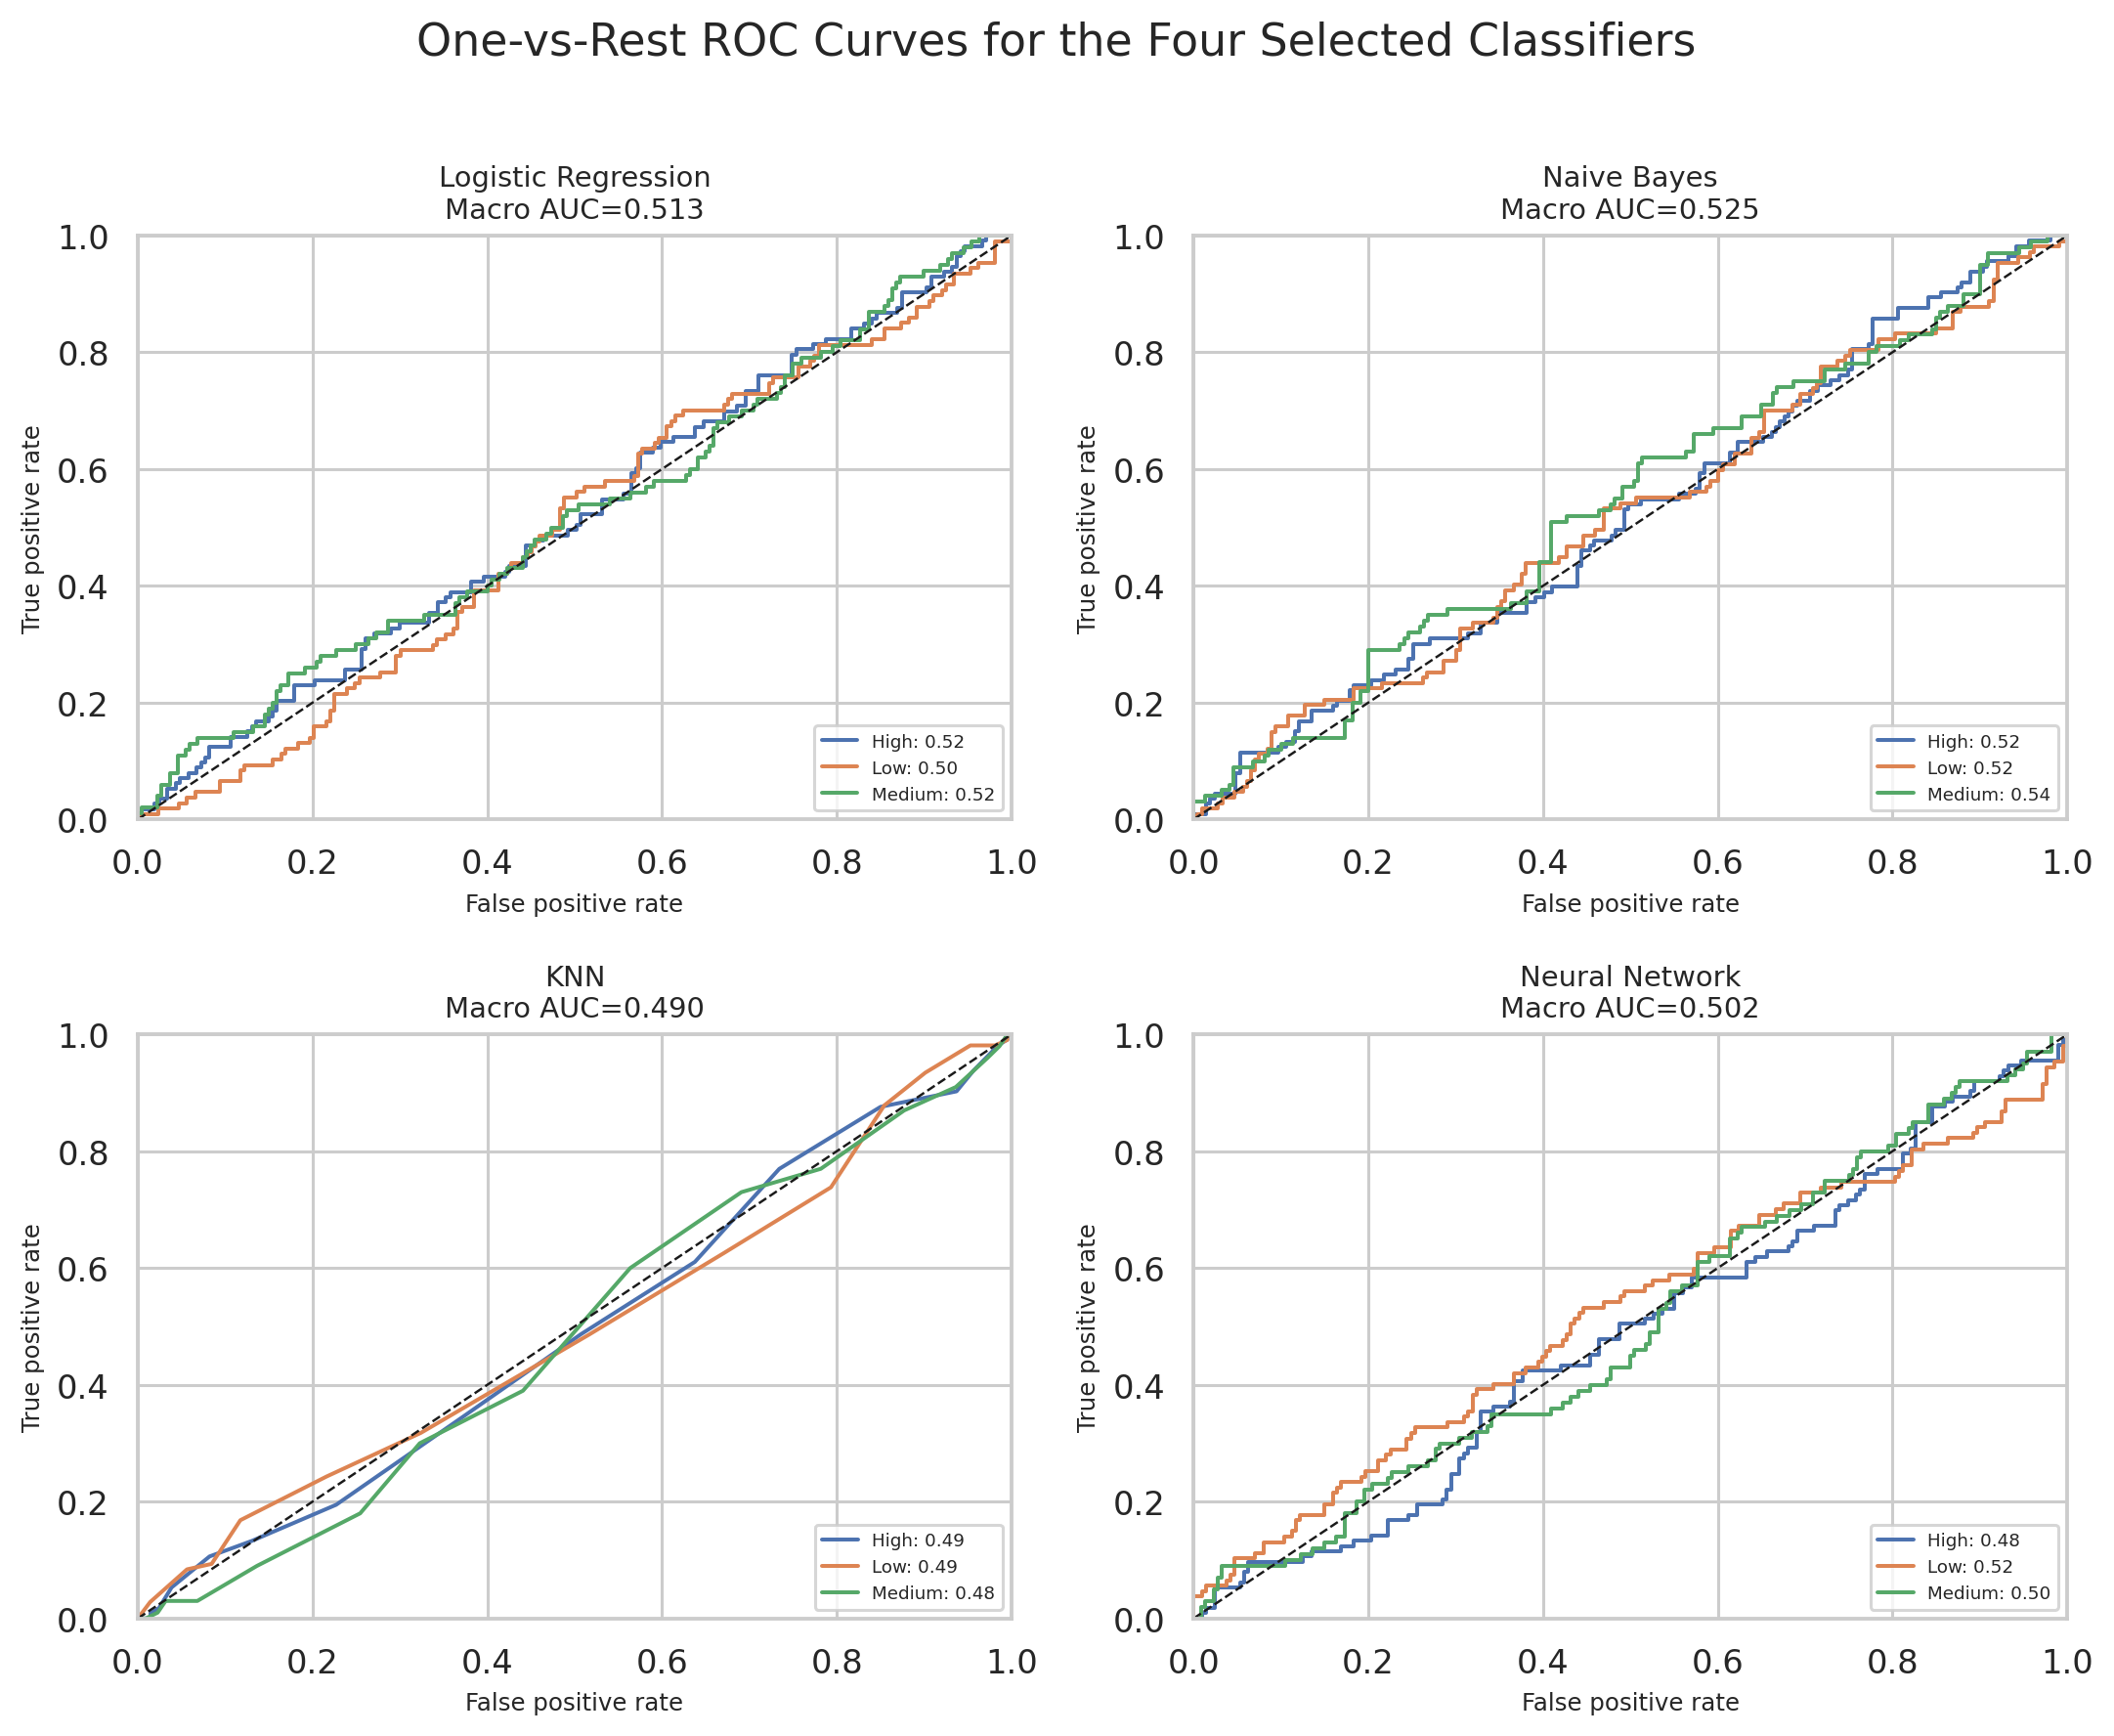

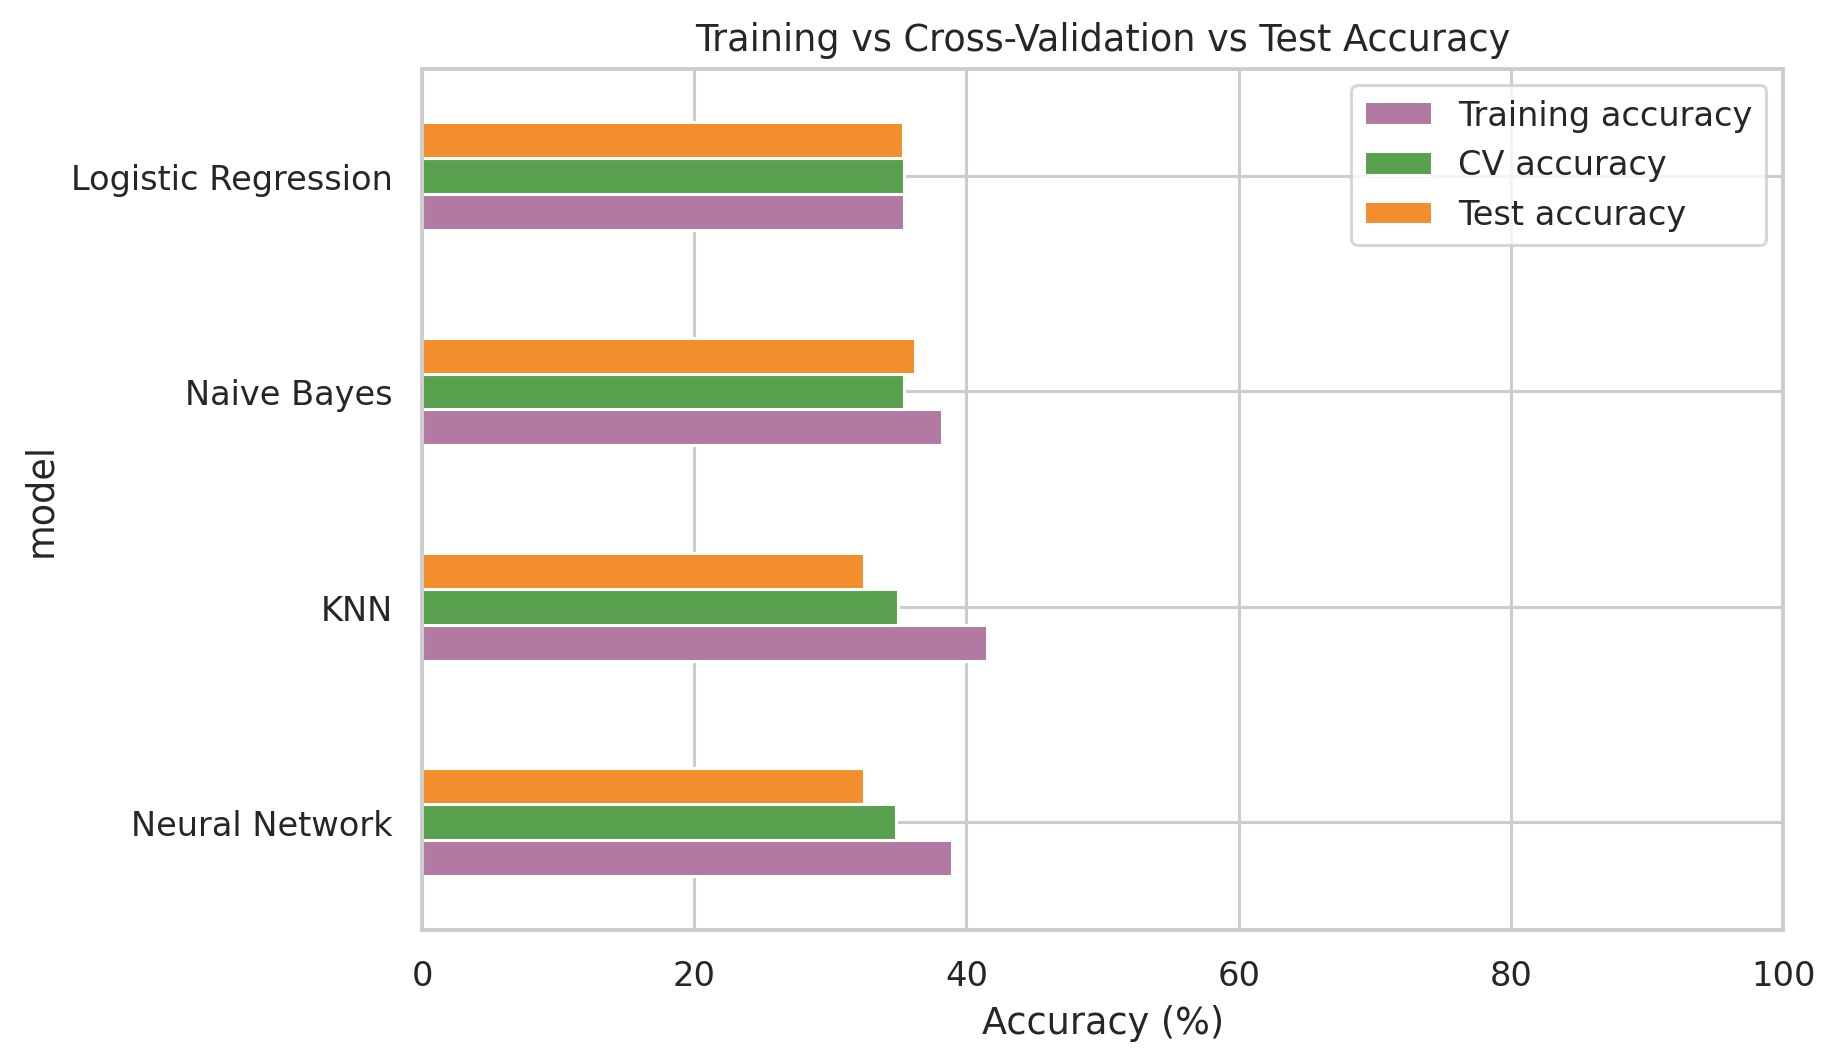

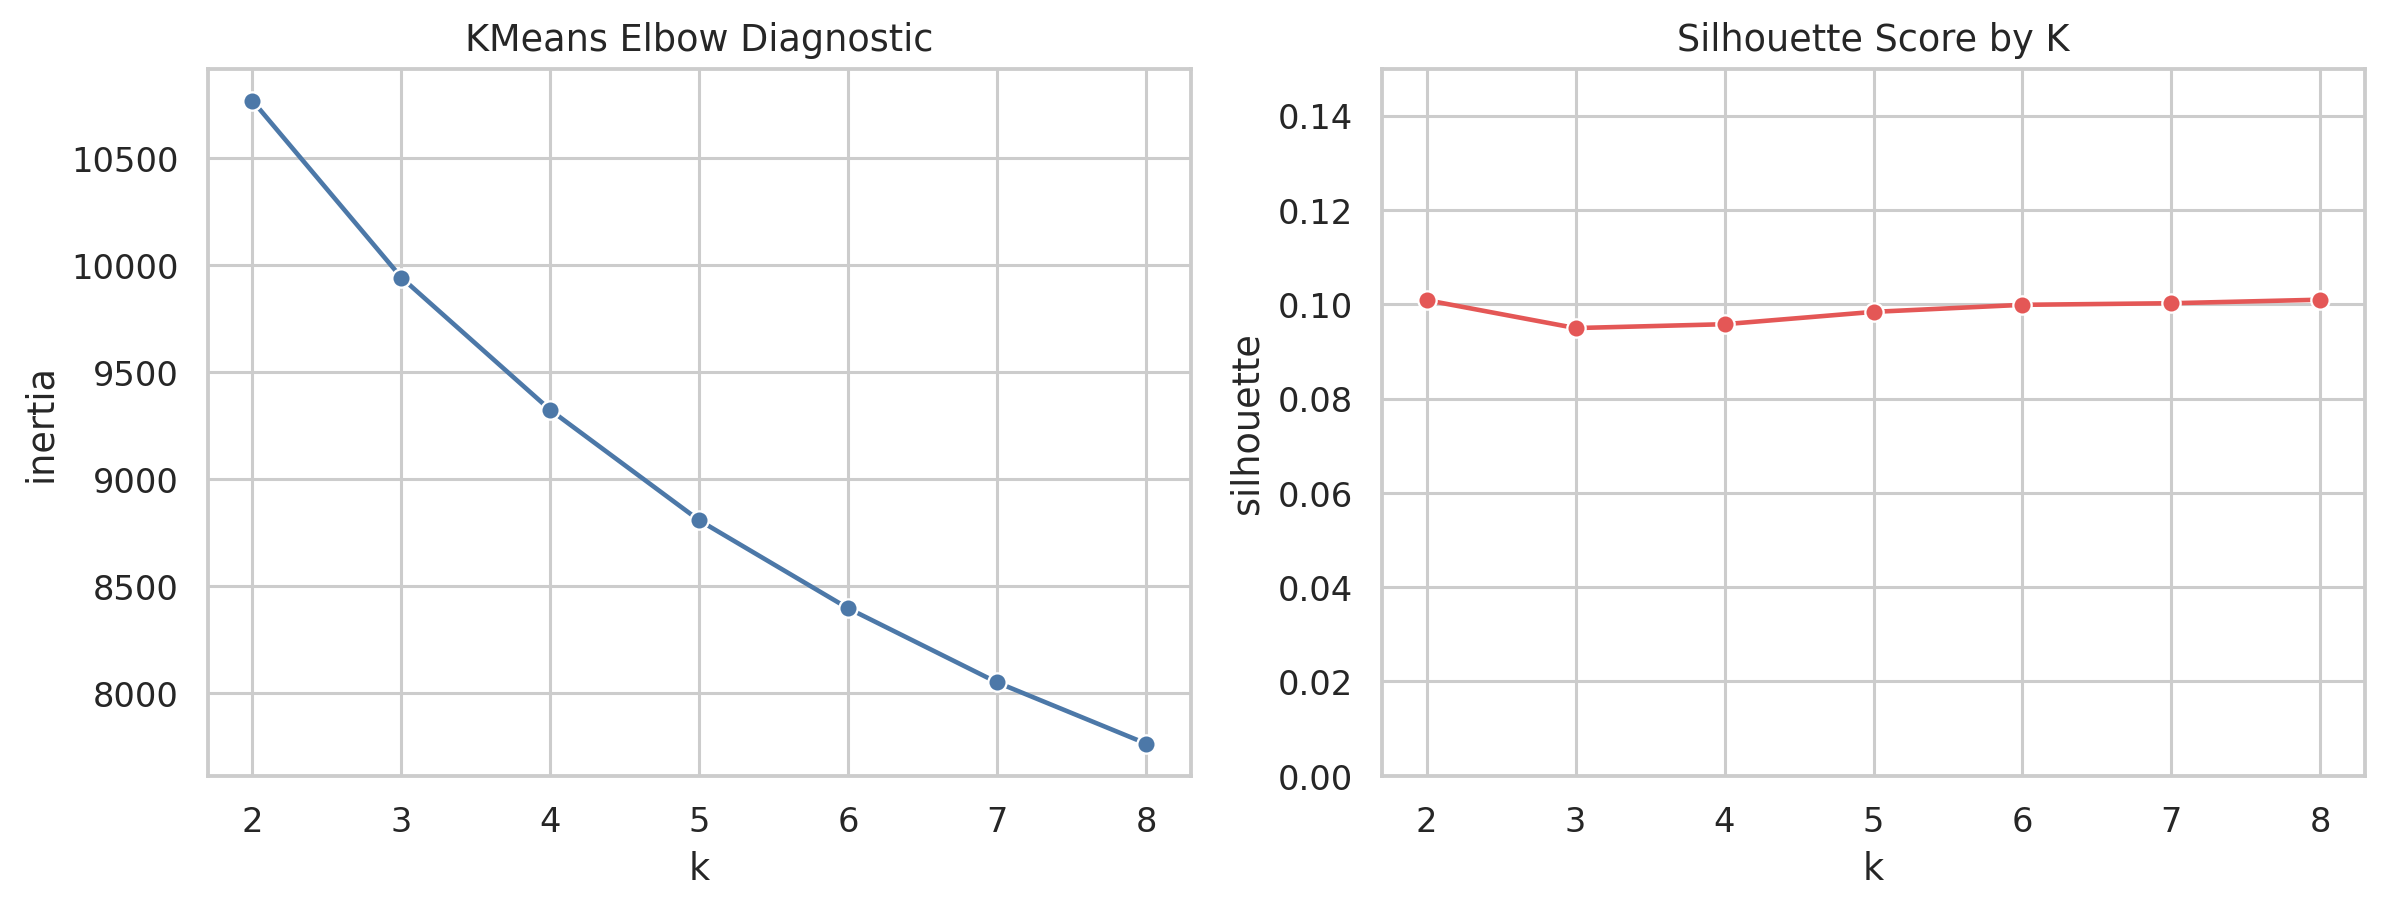

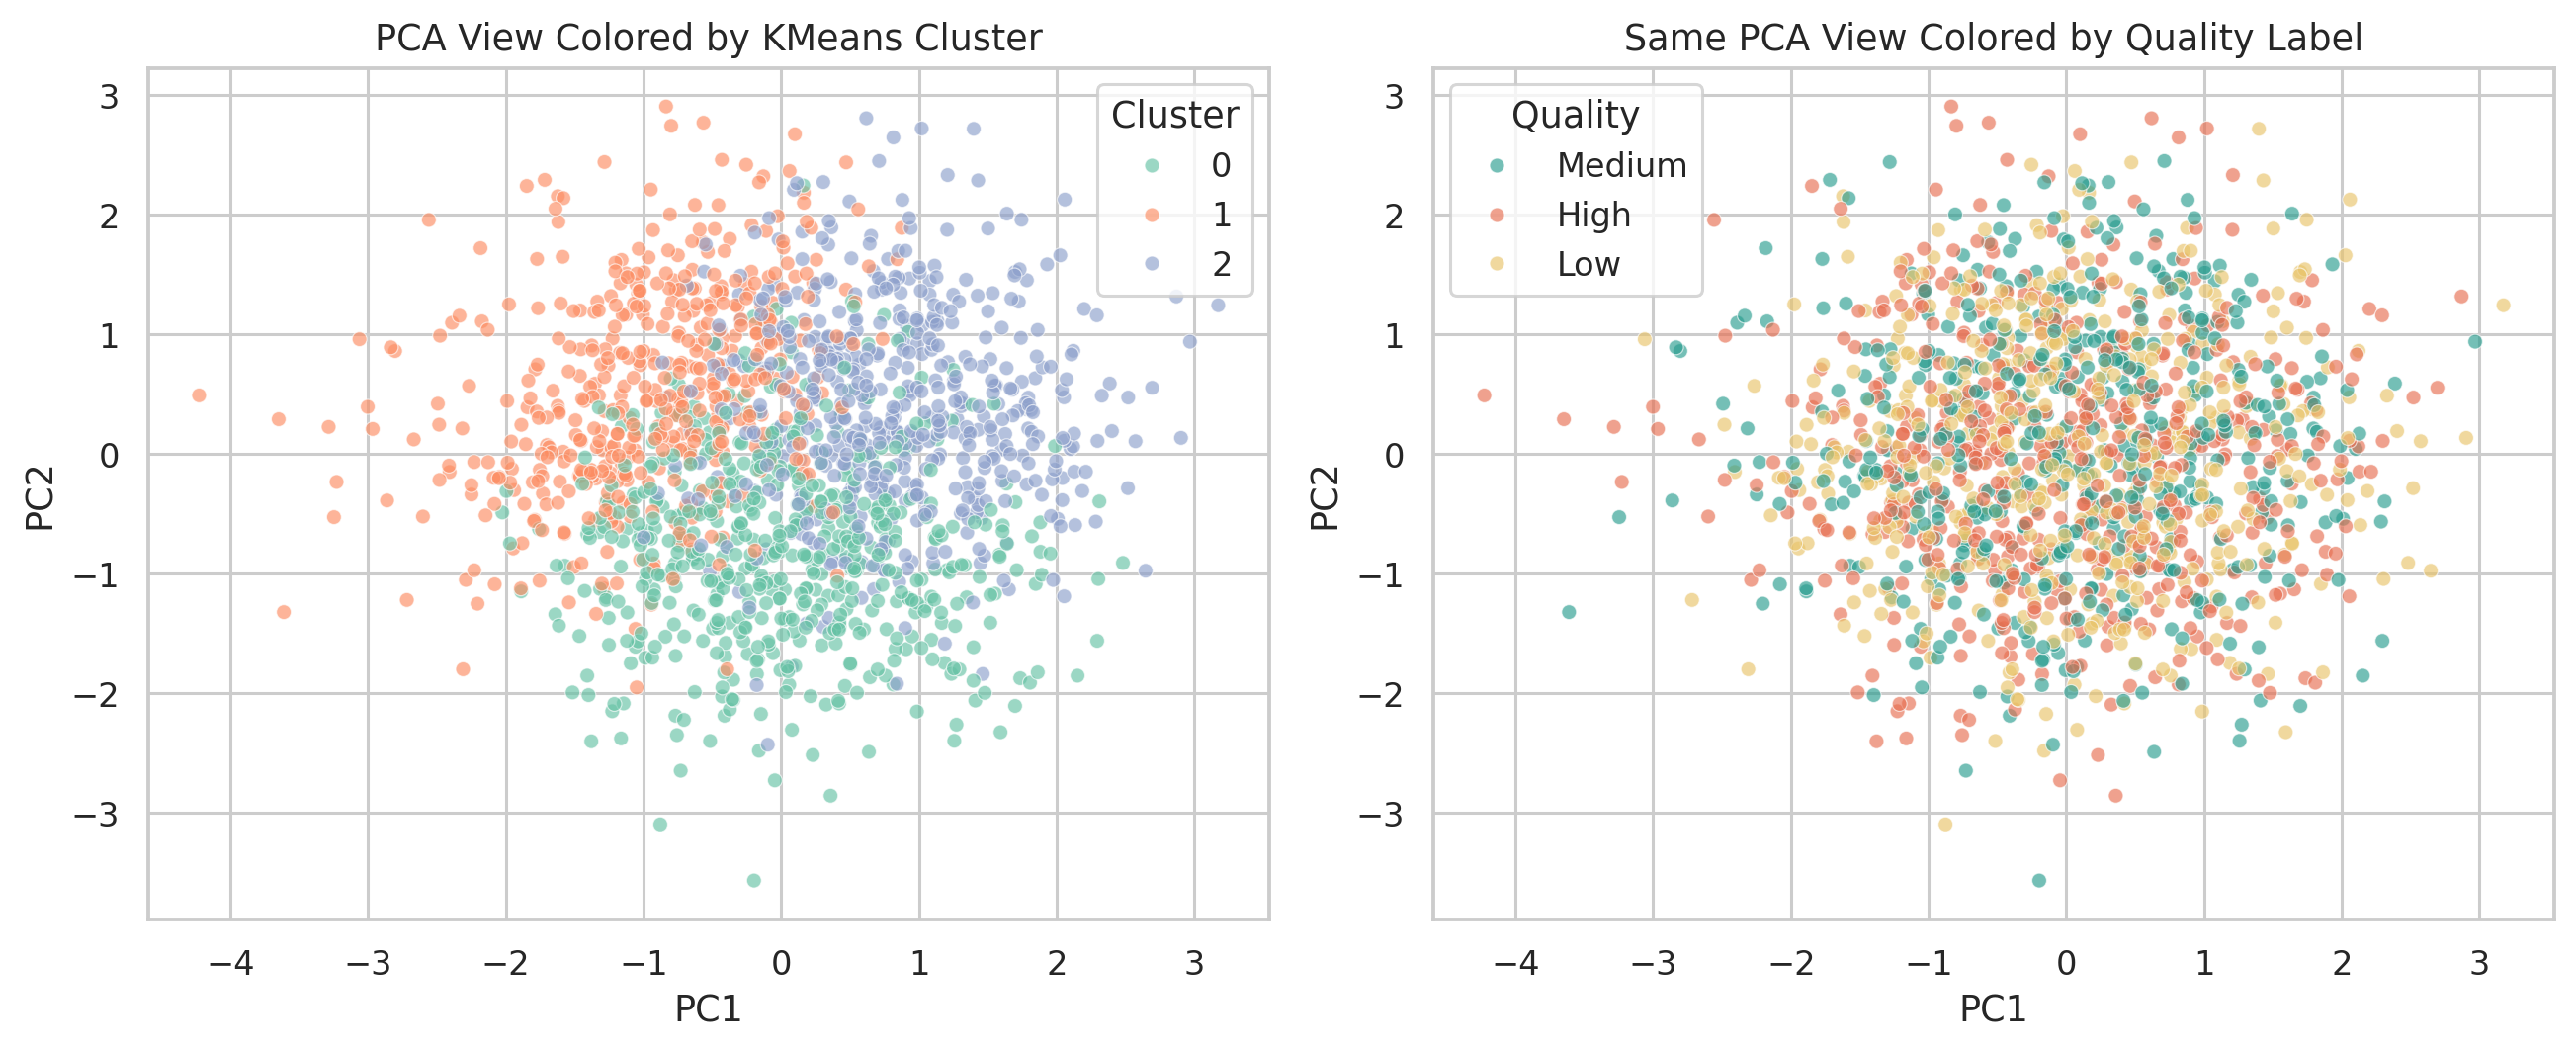

In [1]:
from __future__ import annotations

import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency, f_oneway
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    normalized_mutual_info_score,
    precision_score,
    recall_score,
    roc_curve,
    auc,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler


ROOT = Path.cwd()
DATA_CANDIDATES = [
    Path("software_quality_dataset.csv"),
    ROOT / "upload" / "software_quality_dataset.csv",
    Path("/content/software_quality_dataset.csv"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), DATA_CANDIDATES[0])
OUT_DIR = Path("software_quality_outputs")
OUT_PATH = OUT_DIR / "analysis_results.json"
SEED = 42


def preprocessor(numeric_columns, categorical_columns, scale: bool):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)
    categorical_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [("num", numeric_pipe, numeric_columns), ("cat", categorical_pipe, categorical_columns)],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value


def main():
    warnings.filterwarnings("ignore", category=UserWarning)
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220})

    df = pd.read_csv(DATA_PATH)
    X = df.drop(columns="Quality_Label")
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(df["Quality_Label"])
    classes = label_encoder.classes_.tolist()

    missing = df.isna().sum().sort_values(ascending=False)
    class_counts = df["Quality_Label"].value_counts()
    class_percentages = df["Quality_Label"].value_counts(normalize=True).mul(100)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    missing_nonzero = missing[missing > 0]
    sns.barplot(x=missing_nonzero.index, y=missing_nonzero.values, ax=axes[0], color="#4C78A8")
    axes[0].set_title("Missing Values by Feature")
    axes[0].set_ylabel("Missing cells")
    axes[0].tick_params(axis="x", rotation=20)
    for index, value in enumerate(missing_nonzero.values):
        axes[0].text(index, value + 2, str(value), ha="center", fontsize=9)
    order = ["High", "Medium", "Low"]
    ordered_counts = class_counts.reindex(order)
    sns.barplot(
        x=ordered_counts.index,
        y=ordered_counts.values,
        hue=ordered_counts.index,
        palette=["#2A9D8F", "#E9C46A", "#E76F51"],
        legend=False,
        ax=axes[1],
    )
    axes[1].set_title("Quality Label Distribution")
    axes[1].set_ylabel("Rows")
    for index, label in enumerate(order):
        axes[1].text(
            index,
            class_counts[label] + 8,
            f"{class_counts[label]}\n({class_percentages[label]:.1f}%)",
            ha="center",
            fontsize=9,
        )
    fig.tight_layout()
    fig.savefig(OUT_DIR / "data_quality_and_class_balance.png", bbox_inches="tight")
    plt.show()

    eda_numeric = df.copy()
    eda_numeric["Has_Unit_Tests_Code"] = (eda_numeric["Has_Unit_Tests"] == "Yes").astype(int)
    eda_numeric["Quality_Label_Code"] = label_encoder.transform(df["Quality_Label"])
    correlation_columns = X.select_dtypes(include=np.number).columns.tolist() + [
        "Has_Unit_Tests_Code",
        "Quality_Label_Code",
    ]
    correlation = eda_numeric[correlation_columns].corr()
    plt.figure(figsize=(10.5, 8))
    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        linewidths=0.4,
        cbar_kws={"shrink": 0.8},
    )
    plt.title("Pearson Correlation Heatmap (Encoded Target Shown with Caution)")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "correlation_heatmap.png", bbox_inches="tight")
    plt.show()

    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for axis, feature in zip(axes.flat, numeric_features):
        sns.boxplot(
            data=df,
            x="Quality_Label",
            y=feature,
            order=["High", "Medium", "Low"],
            hue="Quality_Label",
            palette="Set2",
            legend=False,
            ax=axis,
            showfliers=False,
        )
        axis.set_title(feature.replace("_", " "))
        axis.set_xlabel("")
    axes.flat[-1].axis("off")
    fig.suptitle("Numeric Predictors by Quality Class", fontsize=15, y=1.01)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "numeric_features_by_target.png", bbox_inches="tight")
    plt.show()

    anova_rows = []
    for feature in numeric_features:
        groups = [
            df.loc[df["Quality_Label"] == label, feature].dropna()
            for label in ["High", "Medium", "Low"]
        ]
        statistic, p_value = f_oneway(*groups)
        anova_rows.append({"feature": feature, "F": statistic, "p_value": p_value})
    anova_df = pd.DataFrame(anova_rows).sort_values("p_value")
    unit_tests_table = pd.crosstab(df["Has_Unit_Tests"], df["Quality_Label"])
    chi_square, chi_p_value, _, _ = chi2_contingency(unit_tests_table)
    cramers_v = np.sqrt(
        chi_square / (unit_tests_table.to_numpy().sum() * (min(unit_tests_table.shape) - 1))
    )

    numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
    categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=SEED, stratify=y
    )

    scaled = preprocessor(numeric_columns, categorical_columns, scale=True)

    model_specs = {
        "KNN": (
            scaled,
            KNeighborsClassifier(),
            {
                "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41, 51],
                "model__weights": ["uniform", "distance"],
                "model__p": [1, 2],
            },
        ),
        "Logistic Regression": (
            scaled,
            LogisticRegression(max_iter=2500, random_state=SEED),
            {
                "model__C": [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
                "model__class_weight": [None, "balanced"],
            },
        ),
        "Naive Bayes": (
            scaled,
            GaussianNB(),
            {"model__var_smoothing": np.logspace(-12, -1, 12).tolist()},
        ),
        "Neural Network": (
            scaled,
            MLPClassifier(
                max_iter=1500,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=40,
                random_state=SEED,
            ),
            {
                "model__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
                "model__alpha": [0.0001, 0.001, 0.01],
                "model__learning_rate_init": [0.0005, 0.001, 0.005],
            },
        ),
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    results = []
    fitted_models = {}
    predictions = {}
    probabilities = {}
    for name, (prep, estimator, grid) in model_specs.items():
        started = time.time()
        pipe = Pipeline([("preprocessor", prep), ("model", estimator)])
        search = GridSearchCV(
            pipe,
            grid,
            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
            cv=cv,
            n_jobs=-1,
            refit="accuracy",
            return_train_score=True,
        )
        search.fit(X_train, y_train)
        best = search.best_estimator_
        pred = best.predict(X_test)
        prob = best.predict_proba(X_test)
        row = {
            "model": name,
            "best_params": search.best_params_,
            "cv_accuracy": search.best_score_,
            "cv_accuracy_std": search.cv_results_["std_test_accuracy"][search.best_index_],
            "cv_train_accuracy": search.cv_results_["mean_train_accuracy"][search.best_index_],
            "cv_macro_f1": search.cv_results_["mean_test_macro_f1"][search.best_index_],
            "cv_macro_f1_std": search.cv_results_["std_test_macro_f1"][search.best_index_],
            "cv_train_macro_f1": search.cv_results_["mean_train_macro_f1"][search.best_index_],
            "test_accuracy": accuracy_score(y_test, pred),
            "test_balanced_accuracy": balanced_accuracy_score(y_test, pred),
            "test_precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
            "test_recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
            "test_f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
            "test_roc_auc_ovr_macro": roc_auc_score(
                y_test, prob, multi_class="ovr", average="macro"
            ),
            "test_log_loss": log_loss(y_test, prob, labels=np.arange(len(classes))),
            "confusion_matrix": confusion_matrix(y_test, pred).tolist(),
            "elapsed_seconds": time.time() - started,
        }
        results.append(row)
        fitted_models[name] = best
        predictions[name] = pred
        probabilities[name] = prob
        print(
            f"{name:22s} CV accuracy={100*row['cv_accuracy']:.2f}% "
            f"Test accuracy={100*row['test_accuracy']:.2f}% "
            f"Macro F1={100*row['test_f1_macro']:.2f}% "
            f"AUC={row['test_roc_auc_ovr_macro']:.3f} ({row['elapsed_seconds']:.1f}s)",
            flush=True,
        )

    baseline = float(np.max(np.bincount(y_test)) / len(y_test))
    results_df = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False)
    results_df.to_csv(OUT_DIR / "model_results.csv", index=False)
    anova_df.to_csv(OUT_DIR / "anova_results.csv", index=False)

    accuracy_frame = results_df.sort_values("test_accuracy")
    figure, axis = plt.subplots(figsize=(8.5, 4.8))
    bars = axis.barh(
        accuracy_frame["model"],
        100 * accuracy_frame["test_accuracy"],
        color=["#4C78A8", "#59A14F", "#F28E2B", "#B279A2"],
    )
    axis.axvline(
        100 * baseline,
        color="black",
        linestyle="--",
        linewidth=1.4,
        label=f"Majority baseline: {100 * baseline:.2f}%",
    )
    axis.bar_label(
        bars,
        labels=[f"{100 * value:.2f}%" for value in accuracy_frame["test_accuracy"]],
        padding=3,
        fontsize=9,
    )
    axis.set_xlim(0, max(45, 100 * accuracy_frame["test_accuracy"].max() + 6))
    axis.set_xlabel("Hold-out accuracy (%)")
    axis.set_title("Accuracy Comparison for the Four Selected Classifiers")
    axis.legend(loc="lower right", fontsize=8)
    figure.tight_layout()
    figure.savefig(OUT_DIR / "accuracy_percentage_comparison.png", bbox_inches="tight")
    plt.show()

    metric_columns = [
        "test_accuracy",
        "test_precision_macro",
        "test_recall_macro",
        "test_f1_macro",
    ]
    metric_labels = ["Accuracy", "Macro precision", "Macro recall", "Macro F1"]
    plot_frame = (
        results_df.sort_values("test_accuracy").set_index("model")[metric_columns] * 100
    )
    plot_frame.columns = metric_labels
    axis = plot_frame.plot(
        kind="barh",
        figsize=(8.5, 5),
        width=0.82,
        color=["#4C78A8", "#72B7B2", "#F2CF5B", "#E45756"],
    )
    axis.axvline(
        100 * baseline,
        color="black",
        linestyle="--",
        linewidth=1.4,
        label=f"Majority baseline ({100 * baseline:.2f}%)",
    )
    axis.set_xlim(0, 45)
    axis.set_xlabel("Percentage (%)")
    axis.set_title("Hold-out Classification Metrics (%)")
    axis.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "supervised_metric_comparison.png", bbox_inches="tight")
    plt.show()

    figure, axes = plt.subplots(2, 2, figsize=(10, 8))
    flat_axes = axes.flat
    for axis, name in zip(flat_axes, results_df["model"]):
        matrix = confusion_matrix(y_test, predictions[name])
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=classes,
            yticklabels=classes,
            ax=axis,
        )
        axis.set_title(name, fontsize=10)
        axis.set_xlabel("Predicted")
        axis.set_ylabel("Actual")
    figure.suptitle("Confusion Matrices for the Four Selected Classifiers", fontsize=15, y=1.01)
    figure.tight_layout()
    figure.savefig(OUT_DIR / "all_confusion_matrices.png", bbox_inches="tight")
    plt.show()

    y_test_binary = np.eye(len(classes))[y_test]
    figure, axes = plt.subplots(2, 2, figsize=(10, 8))
    flat_axes = axes.flat
    for axis, name in zip(flat_axes, results_df["model"]):
        probability = probabilities[name]
        for class_index, class_name in enumerate(classes):
            false_positive, true_positive, _ = roc_curve(
                y_test_binary[:, class_index], probability[:, class_index]
            )
            axis.plot(
                false_positive,
                true_positive,
                linewidth=1.3,
                label=f"{class_name}: {auc(false_positive, true_positive):.2f}",
            )
        axis.plot([0, 1], [0, 1], "k--", linewidth=0.8)
        model_auc = results_df.loc[
            results_df["model"] == name, "test_roc_auc_ovr_macro"
        ].iloc[0]
        axis.set_title(f"{name}\nMacro AUC={model_auc:.3f}", fontsize=9.5)
        axis.set_xlim(0, 1)
        axis.set_ylim(0, 1)
        axis.legend(fontsize=6, loc="lower right")
        axis.set_xlabel("False positive rate", fontsize=8)
        axis.set_ylabel("True positive rate", fontsize=8)
    figure.suptitle("One-vs-Rest ROC Curves for the Four Selected Classifiers", fontsize=15, y=1.01)
    figure.tight_layout()
    figure.savefig(OUT_DIR / "all_roc_curves.png", bbox_inches="tight")
    plt.show()

    generalization = (
        results_df.sort_values("cv_accuracy").set_index("model")[
            ["cv_train_accuracy", "cv_accuracy", "test_accuracy"]
        ]
        * 100
    )
    generalization.columns = ["Training accuracy", "CV accuracy", "Test accuracy"]
    generalization.plot(
        kind="barh",
        figsize=(8.5, 5),
        color=["#B279A2", "#59A14F", "#F28E2B"],
    )
    plt.xlim(0, 100)
    plt.xlabel("Accuracy (%)")
    plt.title("Training vs Cross-Validation vs Test Accuracy")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "generalization_comparison.png", bbox_inches="tight")
    plt.show()

    unsup_preprocessor = preprocessor(numeric_columns, categorical_columns, scale=True)
    X_all_scaled = unsup_preprocessor.fit_transform(X)
    cluster_metrics = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
        labels = km.fit_predict(X_all_scaled)
        cluster_metrics.append(
            {"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_all_scaled, labels)}
        )
    cluster_frame = pd.DataFrame(cluster_metrics)
    figure, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    sns.lineplot(data=cluster_frame, x="k", y="inertia", marker="o", ax=axes[0], color="#4C78A8")
    axes[0].set_title("KMeans Elbow Diagnostic")
    sns.lineplot(
        data=cluster_frame,
        x="k",
        y="silhouette",
        marker="o",
        ax=axes[1],
        color="#E45756",
    )
    axes[1].set_title("Silhouette Score by K")
    axes[1].set_ylim(0, max(0.15, cluster_frame["silhouette"].max() + 0.02))
    figure.tight_layout()
    figure.savefig(OUT_DIR / "kmeans_k_selection.png", bbox_inches="tight")
    plt.show()
    km3 = KMeans(n_clusters=3, n_init=50, random_state=SEED)
    cluster3 = km3.fit_predict(X_all_scaled)
    contingency = pd.crosstab(cluster3, df["Quality_Label"])
    cost = contingency.to_numpy().max() - contingency.to_numpy()
    rows, cols = linear_sum_assignment(cost)
    mapped_correct = contingency.to_numpy()[rows, cols].sum()
    pca = PCA(n_components=2, random_state=SEED).fit_transform(X_all_scaled)
    cluster_plot = pd.DataFrame(
        {
            "PC1": pca[:, 0],
            "PC2": pca[:, 1],
            "Cluster": cluster3.astype(str),
            "Quality": df["Quality_Label"].values,
        }
    )
    figure, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.scatterplot(
        data=cluster_plot,
        x="PC1",
        y="PC2",
        hue="Cluster",
        palette="Set2",
        s=24,
        alpha=0.65,
        ax=axes[0],
    )
    axes[0].set_title("PCA View Colored by KMeans Cluster")
    sns.scatterplot(
        data=cluster_plot,
        x="PC1",
        y="PC2",
        hue="Quality",
        palette=["#2A9D8F", "#E76F51", "#E9C46A"],
        s=24,
        alpha=0.65,
        ax=axes[1],
    )
    axes[1].set_title("Same PCA View Colored by Quality Label")
    figure.tight_layout()
    figure.savefig(OUT_DIR / "kmeans_pca_comparison.png", bbox_inches="tight")
    plt.show()

    payload = {
        "dataset": {
            "rows": len(df),
            "predictors": X.shape[1],
            "numeric_predictors": numeric_columns,
            "categorical_predictors": categorical_columns,
            "class_labels": classes,
            "class_counts": df["Quality_Label"].value_counts().to_dict(),
            "class_percentages": class_percentages.to_dict(),
            "missing_counts": df.isna().sum().to_dict(),
            "rows_with_any_missing": int(df.isna().any(axis=1).sum()),
            "duplicate_rows": int(df.duplicated().sum()),
            "train_rows": len(X_train),
            "test_rows": len(X_test),
            "majority_test_baseline": baseline,
        },
        "association_tests": {
            "anova": anova_df.to_dict(orient="records"),
            "unit_tests_chi_square": chi_square,
            "unit_tests_p_value": chi_p_value,
            "unit_tests_cramers_v": cramers_v,
            "encoded_target_correlations": correlation["Quality_Label_Code"]
            .drop("Quality_Label_Code")
            .to_dict(),
        },
        "supervised_results": results,
        "kmeans": {
            "k_sweep": cluster_metrics,
            "k3_silhouette": silhouette_score(X_all_scaled, cluster3),
            "k3_ari": adjusted_rand_score(y, cluster3),
            "k3_nmi": normalized_mutual_info_score(y, cluster3),
            "k3_posthoc_mapped_accuracy": mapped_correct / len(df),
            "contingency": contingency.to_dict(),
            "pca_explained_variance": PCA(n_components=2).fit(X_all_scaled).explained_variance_ratio_.sum(),
            "pca_coordinates_sample": pca[:10].tolist(),
        },
        "versions": {
            "pandas": pd.__version__,
        },
    }
    OUT_PATH.write_text(json.dumps(json_safe(payload), indent=2), encoding="utf-8")
    print(f"Saved {OUT_PATH}")


if __name__ == "__main__":
    main()


## Supervised comparison table

In [2]:
results_path = Path("software_quality_outputs/analysis_results.json")
analysis = json.loads(results_path.read_text(encoding="utf-8"))
model_results = pd.DataFrame(analysis["supervised_results"]).sort_values(
    "cv_accuracy", ascending=False
)
comparison = model_results[[
    "model", "cv_accuracy", "test_accuracy", "test_precision_macro",
    "test_recall_macro", "test_f1_macro", "test_roc_auc_ovr_macro"
]].copy()
for column in ["cv_accuracy", "test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro"]:
    comparison[column] *= 100
comparison.columns = ["Model", "CV Accuracy (%)", "Test Accuracy (%)", "Precision (%)", "Recall (%)", "F1 (%)", "Macro OvR AUC"]
display(comparison.style.format({column: "{:.2f}" for column in comparison.columns[1:6]}).format({"Macro OvR AUC": "{:.3f}"}))

Model,CV Accuracy (%),Test Accuracy (%),Precision (%),Recall (%),F1 (%),Macro OvR AUC
Logistic Regression,35.391,35.312,11.771,33.333,17.398,0.513
Naive Bayes,35.391,36.250,36.524,35.969,35.460,0.525
KNN,35.000,32.500,32.605,32.112,31.822,0.490
Neural Network,34.844,32.500,34.000,32.828,31.705,0.502


## KMeans results

In [3]:
kmeans_results = analysis["kmeans"]
display(pd.DataFrame(kmeans_results["k_sweep"]).style.format(precision=4))
print("K=3 silhouette:", round(kmeans_results["k3_silhouette"], 4))
print("K=3 ARI:", round(kmeans_results["k3_ari"], 6))
print("K=3 NMI:", round(kmeans_results["k3_nmi"], 6))
print("Post-hoc mapped accuracy:", round(kmeans_results["k3_posthoc_mapped_accuracy"], 4))

k,inertia,silhouette
2,10766.3127,0.1009
3,9940.7799,0.0950
4,9322.4392,0.0958
5,8807.3825,0.0984
6,8396.8844,0.0999
7,8051.0268,0.1002
8,7765.7752,0.1010


## Final evidence-based interpretation

In [4]:
holdout_winner = model_results.sort_values("test_accuracy", ascending=False).iloc[0]
cv_winner = model_results.iloc[0]
baseline = analysis["dataset"]["majority_test_baseline"]
print(
    f"Hold-out leader: {holdout_winner['model']} | "
    f"accuracy={100*holdout_winner['test_accuracy']:.2f}% | "
    f"macro F1={100*holdout_winner['test_f1_macro']:.2f}% | "
    f"macro OvR AUC={holdout_winner['test_roc_auc_ovr_macro']:.4f}"
)
print(
    f"Cross-validation leader: {cv_winner['model']} | "
    f"CV accuracy={100*cv_winner['cv_accuracy']:.2f}%"
)
print(f"Majority baseline accuracy={100*baseline:.2f}%")
print(
    "Conclusion: no supervised model demonstrates strong discrimination, "
    "and KMeans does not recover the supplied quality labels. The limiting "
    "factor is weak predictor-to-label signal, not a missing algorithm."
)

Hold-out leader: Naive Bayes | accuracy=36.25% | macro F1=35.46% | macro OvR AUC=0.5252
Cross-validation leader: Logistic Regression | CV accuracy=35.39%
Majority baseline accuracy=35.31%
Conclusion: no supervised model demonstrates strong discrimination, and KMeans does not recover the supplied quality labels.


## References

1. CSE422 Lab Project Report Template, supplied course document.
2. CSE422 EDA Lab notebook, supplied reference.
3. scikit-learn official documentation for pipelines, model evaluation, multiclass ROC, KMeans, and silhouette analysis.
4. seaborn official documentation for heatmaps.